# 02 - Model development: which model, which threshold, and can I trust it?

**Goal:** choose a model and its alert threshold, then check the result before trusting it.
`src/train.py` is the reproducible script. This notebook imports the same functions and runs them step by step,
so every number here comes from the same code. Each section asks a **question**, shows what I found, and ends
with the **decision** it led to.

| Sections | Data used |
|---|---|
| 1-2. Split the data, fit five models | train (60%) |
| 3-5. Thresholds, speed, choice | validation (20%) |
| 6. The result | test (20%), used once, after the choice |
| 7-9. Trust checks: memorizing? later traffic? what drives it? | test and a time-ordered split; they change nothing |
| 10. Two mistakes found by review in an earlier version | |

Run `python -m src.train` first: section 6 checks that this notebook rebuilds the saved model exactly.
Figures 05 and 06 are saved to `reports/figures/`.

In [1]:
import math
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.metrics import precision_recall_curve
from sklearn.tree import export_text

# Repo root, whether the notebook runs from notebooks/ or from the repo root.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))  # import the project code instead of copying it
from src import config
from src.features import load_raw, port_service, prepare_dataset
from src.train import (FEATURES, TARGET, at_threshold, candidate_models, choose_model, comparison, fit_models,
                       results, speed_results, split, threshold_for_budget)

PER_DAY = config.BENIGN_FLOWS_PER_DAY
NAMES = {"dummy": "Dummy", "port_lookup": "Port lookup", "logistic_regression": "Logistic regression",
         "decision_tree": "Decision tree (depth 4)", "hist_gradient_boosting": "Gradient boosting"}

# Large fonts and thick lines so every plot is easy to read.
plt.rcParams.update({
    "figure.figsize": (12, 7),
    "figure.facecolor": "white",
    "font.size": 15,
    "axes.titlesize": 18,
    "axes.titleweight": "bold",
    "axes.labelsize": 16,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 15,
    "lines.linewidth": 3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#d9d9d9",
    "axes.axisbelow": True,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
})

## 1. Split the data

**Question:** I need data to fit the models, data to choose a threshold and a model, and data to report the
result. How do I keep the final number honest?

In [2]:
clean = prepare_dataset(load_raw())  # only exact duplicate rows dropped; flows sorted by time
train, validation, test = split(clean)
parts = {"train": train, "validation": validation, "test": test}
benign = {name: int((part[TARGET] == 0).sum()) for name, part in parts.items()}
pd.DataFrame({
    "flows": {name: f"{len(part):,}" for name, part in parts.items()},
    "share": {name: f"{len(part) / len(clean):.0%}" for name, part in parts.items()},
    "bad flows": {name: f"{part[TARGET].mean():.2%}" for name, part in parts.items()},
    "benign flows": {name: f"{count:,}" for name, count in benign.items()},
    "false alarms the budget allows": {name: f"{count * config.MAX_FALSE_POSITIVE_RATE:.0f}"
                                       for name, count in benign.items()},
})

,flows,share,bad flows,benign flows,false alarms the budget allows
train,"1,178,607",60%,19.89%,"944,132",94
validation,"392,870",20%,19.89%,"314,712",31
test,"392,870",20%,19.89%,"314,712",31


- A stratified 60/20/20 split: every part keeps the same share of bad flows (19.9%).
- The first cut is the same 80/20 as in earlier versions, so the **test set is the same 392,870 flows** as before.
  Old and new results compare like with like.
- The alert budget (0.01% of benign flows) allows only **31 false alarms on validation**. A threshold set on so
  few events is a little noisy, so the test set has to confirm it.

**Decision:** fit on train only. Choose each threshold and the model on validation. Use the test set once, at
the end.

## 2. Five models, simplest first

**Question:** what is the simplest model that does the job? Each candidate answers one question:

| Model | The question it answers |
|---|---|
| Dummy | What does "no model" get? Every flow gets the same score: the floor. |
| Port lookup | Is a simple rule enough? Score = share of bad traffic seen in training for this (protocol, port). |
| Logistic regression | Is a linear, explainable model enough? |
| Decision tree, depth 4 | Are a few readable if-then rules enough? |
| Gradient boosting | How much do non-linear patterns add? |

All use default settings, except where a comment in `candidate_models()` says why (for example
`l2_regularization=1.0` for boosting, see section 10). There is no tuning search. The three learned models share
the same preprocessing (`src/features.py`), so they differ only in the classifier.

In [3]:
models = candidate_models()
train_seconds = fit_models(models, train)

Training seconds: dummy 0.0, port_lookup 0.4, logistic_regression 4.3, decision_tree 2.8, hist_gradient_boosting 5.8


The decision tree is the readable one. This is the whole model as rules. `weights` = [benign, bad] training
flows in each leaf.

In [4]:
tree = models["decision_tree"]
print(export_text(tree[-1], feature_names=list(tree[:-1].get_feature_names_out()), show_weights=True))

|--- numeric__duration <= -0.24
|   |--- port_range__dest_port_well_known <= 0.50
|   |   |--- proto__proto_6 <= 0.50
|   |   |   |--- port__dest_port_infrequent_sklearn <= 0.50
|   |   |   |   |--- weights: [14.00, 14823.00] class: 1
|   |   |   |--- port__dest_port_infrequent_sklearn >  0.50
|   |   |   |   |--- weights: [141.00, 313.00] class: 1
|   |   |--- proto__proto_6 >  0.50
|   |   |   |--- port__dest_port_infrequent_sklearn <= 0.50
|   |   |   |   |--- weights: [889305.00, 8574.00] class: 0
|   |   |   |--- port__dest_port_infrequent_sklearn >  0.50
|   |   |   |   |--- weights: [483.00, 10126.00] class: 1
|   |--- port_range__dest_port_well_known >  0.50
|   |   |--- port__dest_port_67 <= 0.50
|   |   |   |--- proto__proto_6 <= 0.50
|   |   |   |   |--- weights: [68.00, 224.00] class: 1
|   |   |   |--- proto__proto_6 >  0.50
|   |   |   |   |--- weights: [45.00, 35599.00] class: 1
|   |   |--- port__dest_port_67 >  0.50
|   |   |   |--- weights: [1005.00, 0.00] class: 0
|-

In [5]:
# The numeric splits above are in scaled log units (log1p, then StandardScaler). The same splits in raw units:
column_transformer, nodes = tree.named_steps["preprocess"], tree[-1].tree_
scaler = column_transformer.named_transformers_["numeric"].named_steps["scale"]
names = column_transformer.get_feature_names_out()
for node in range(nodes.node_count):
    name = names[nodes.feature[node]] if nodes.children_left[node] != -1 else ""  # -1 = a leaf
    if name.startswith("numeric__"):
        column = name.removeprefix("numeric__")
        i = config.NUMERIC_COLS.index(column)
        raw = np.expm1(scaler.mean_[i] + nodes.threshold[node] * scaler.scale_[i])
        print(f"{name} <= {nodes.threshold[node]:.2f}   means   {column} <= {raw:,.4g}")

numeric__duration <= -0.24   means   duration <= 0.003528
numeric__bytes_out <= 0.38   means   bytes_out <= 1,021
numeric__num_pkts_in <= -0.28   means   num_pkts_in <= 0.4142
numeric__duration <= -0.22   means   duration <= 0.01857
numeric__num_pkts_in <= -0.28   means   num_pkts_in <= 0.4142


The tree reads like an analyst's checklist:

- **Very short flows** (under 3.5 ms) are mostly bad: UDP or ICMP probes, TCP to well-known ports (below 1024),
  and TCP to rare ports. Two exceptions are benign: DHCP (port 67), and TCP to common ports such as Elasticsearch
  (9200) or reply ports (889,305 benign vs 8,574 bad training flows).
- **Longer flows** that send under 1 KB and get packets back are bad, unless they go to Elasticsearch (9200).

The catch: most leaves are mixed. The biggest bad leaf holds 159,320 bad training flows but also 1,976 benign
ones, while the budget allows about 94 on train. Section 3 shows what that does inside the budget.

**Decision:** keep the tree as the readable candidate; the budget decides whether it is good enough.

## 3. One alert threshold per model, on validation

**Question:** where does each model draw the line between "alert" and "no alert"?

The business sets the budget, not the model: at most **0.01% of benign flows** may be flagged, about **157 false
alarms a day** on this network (`docs/business_framing.md`). Each model's threshold is the **lowest score that
stays inside that budget on validation**: the most bad traffic it can catch without breaking the budget. Each model
gets its own threshold, because their scores mean different things.

In [6]:
on_validation = results(models, validation)
table = on_validation.add_prefix("val_")
comparison(table).assign(threshold=on_validation["threshold"].map("{:.4f}".format))

,val recall,val alarms/day,val PR-AUC,threshold
dummy,0.0%,0,0.199,inf
port_lookup,91.8%,155,0.966,0.2000
logistic_regression,88.9%,155,0.992,0.9935
decision_tree,22.8%,145,0.963,0.9959
hist_gradient_boosting,96.5%,15,0.996,0.9101


Why does the tree catch so little? Its leaves on validation, from the most to the least suspicious. A leaf is
flagged as a whole, so the threshold can only stop between leaves:

In [7]:
y_val = validation[TARGET].to_numpy()
tree_scores = models["decision_tree"].predict_proba(validation[FEATURES])[:, 1]
leaves = (pd.DataFrame({"leaf score": tree_scores, "benign": y_val == 0, "bad": y_val == 1})
          .groupby("leaf score").sum().sort_index(ascending=False))
leaves["benign so far"] = leaves["benign"].cumsum()
leaves["recall so far"] = (leaves["bad"].cumsum() / leaves["bad"].sum()).map("{:.1%}".format)
leaves.head(5)

,benign,bad,benign so far,recall so far
leaf score,,,,
0.999056,7,4884,7,6.2%
0.998738,19,11770,26,21.3%
0.995924,3,1148,29,22.8%
0.987749,651,53339,680,91.0%
0.954473,131,3327,811,95.3%


And why does boosting use only part of the budget?

In [8]:
boost_scores = models["hist_gradient_boosting"].predict_proba(validation[FEATURES])[:, 1]
boost_threshold = on_validation.loc["hist_gradient_boosting", "threshold"]
next_score = boost_scores[boost_scores < boost_threshold].max()
tied = boost_scores == next_score
print(f"Benign validation flows flagged: {((boost_scores >= boost_threshold) & (y_val == 0)).sum()} "
      f"(the budget allows {benign['validation'] * config.MAX_FALSE_POSITIVE_RATE:.0f})")
print(f"The next score down ({next_score:.4f}) is shared by {(tied & (y_val == 0)).sum()} benign "
      f"and {(tied & (y_val == 1)).sum():,} bad flows: identical flows get identical scores")

Benign validation flows flagged: 3 (the budget allows 31)
The next score down (0.9097) is shared by 101 benign and 1,196 bad flows: identical flows get identical scores


- Inside the budget, **boosting catches 96.5%** of bad validation flows, the port lookup 91.8%, logistic
  regression 88.9%, the depth-4 tree only 22.8%. Dummy catches nothing: its threshold is infinity, because it gives
  every flow the same score and cannot flag anything inside the budget.
- **The tree has a good PR-AUC (0.963) but catches little at the budget.** A leaf is flagged as a whole. Its three
  purest leaves hold 29 benign flows (the budget is 31). The next leaf would add 53,339 bad flows, but also 651
  benign ones. Readable rules are too coarse for a budget this strict.
- **Boosting uses only 3 of its 31 allowed false alarms** (about 15 a day). The next score down is shared by 101
  benign flows, because identical flows get identical scores, so the threshold has to stop above them.
- PR-AUC alone would rank logistic regression (0.992) above the port lookup (0.966), but inside the budget the
  lookup catches more. The area hides what happens at the operating point.

**Decision:** each model keeps its own validation threshold, and models are compared at that operating point
(recall inside the budget), not by PR-AUC.

## 4. Speed: can one process keep up?

**Question:** is any model too slow for live traffic?

A flow record arrives only after its connection has ended, so this is **near-real-time** scoring, not inline:
nothing waits for the answer the way a card payment waits for a fraud score. What matters is **throughput**
(keeping up with bursts) and the **time to alert**. First, how fast does traffic arrive?

In [9]:
per_minute = clean["event_time"].dt.floor("min").value_counts()
print(f"Busiest minute: {per_minute.idxmax():%H:%M} UTC, {per_minute.max():,} flows, "
      f"about {per_minute.max() / 60:,.0f} a second (the day's average is {len(clean) / 86_400:,.0f} a second)")
print(f"Speed budget (config.MIN_FLOWS_PER_SECOND): {config.MIN_FLOWS_PER_SECOND:,} flows a second, "
      f"about 10x the busiest minute")

Busiest minute: 17:01 UTC, 26,695 flows, about 445 a second (the day's average is 23 a second)
Speed budget (config.MIN_FLOWS_PER_SECOND): 4,500 flows a second, about 10x the busiest minute


Each model is timed through its whole fitted pipeline (preprocessing + model), called the way the API calls it,
on one CPU thread: batches of 1,000 flows for throughput, and 1,000 single flows for latency. Timings vary a
little from run to run.

In [10]:
speed = speed_results(models, validation[FEATURES])
pd.DataFrame({
    "flows/s in batches of 1,000": speed["flows_per_second"].map("{:,.0f}".format),
    "meets the speed budget": speed["flows_per_second"] >= config.MIN_FLOWS_PER_SECOND,
    "1 flow: p50 ms": speed["single_p50_ms"].map("{:.1f}".format),
    "1 flow: p95 ms": speed["single_p95_ms"].map("{:.1f}".format),
    "flows/s one at a time": (1_000 / speed["single_p50_ms"]).map("{:,.0f}".format),
    "file MB": speed["size_mb"].map("{:.2f}".format),
    "training s": pd.Series(train_seconds).map("{:.1f}".format),
})

,"flows/s in batches of 1,000",meets the speed budget,1 flow: p50 ms,1 flow: p95 ms,flows/s one at a time,file MB,training s
dummy,"68,965,477",True,0.0,0.0,"131,874",0.00,0.0
port_lookup,"1,211,204",True,0.3,0.3,"3,358",0.30,0.4
logistic_regression,"116,328",True,7.7,7.9,131,0.84,4.3
decision_tree,"115,065",True,7.6,7.8,131,0.84,2.8
hist_gradient_boosting,"85,383",True,7.9,8.2,126,1.22,5.8


- **In batches of 1,000, every model is far above the speed budget** on one CPU thread. Boosting scores roughly
  80,000 flows a second, over 15x the budget. No model is too slow.
- **One flow at a time is a different story.** Every call pays a fixed cost of about 8 ms (pandas and the
  preprocessing steps), so the three learned models score only about 130 flows a second one by one: below even the
  busiest minute (445 a second). The cost is in the call, not in the model: logistic regression, the tree and
  boosting take about the same time.
- The model files are small (1.2 MB at most), and every model trains in under 10 seconds.

**Decision:** score flows in small batches (for example every second, or every 1,000 flows), not one by one. That
adds at most about a second to the time to alert. Single-flow latency would matter only for inline scoring, such as
a card payment waiting for an answer. The speed budget excludes no model.

## 5. Choose the model

**Question:** which model do I serve?

**Selection rule**, fixed before looking at the test set: the **highest validation recall inside the alert
budget, among models that meet the speed budget**. Recall within 0.1 point of the best (about 80 bad validation
flows) counts as a tie, and a tie goes to the simpler model (the order in section 2).

In [11]:
table = table.join(speed)
chosen = choose_model(table)
runner_up = table["val_recall"].drop(chosen).idxmax()
margin = table.loc[chosen, "val_recall"] - table.loc[runner_up, "val_recall"]
print(f"Chosen: {chosen}. Next best: {runner_up}, {100 * margin:.1f} points of recall behind "
      f"(about {margin * (y_val == 1).sum():,.0f} bad validation flows).")

Chosen: hist_gradient_boosting. Next best: port_lookup, 4.7 points of recall behind (about 3,647 bad validation flows).


Gradient boosting wins clearly: 4.7 points of recall above the port lookup (about 3,600 more bad validation flows
caught), with a tenth of its false alarms (15 a day instead of 155). It is not a tie, and it meets the speed budget.

**Decision:** serve gradient boosting. The port lookup stays as the honest answer to "why machine learning?".

## 6. The test set, once

**Question:** does the choice hold on data that no decision has used?

Every model is scored on the test set at the threshold it got on validation. Nothing is re-tuned.

In [12]:
on_test = results(models, test, on_validation["threshold"])
table = table.join(on_test.drop(columns="threshold").add_prefix("test_"))
comparison(table)

,val recall,val alarms/day,val PR-AUC,test recall,test alarms/day,test PR-AUC,flows/s,1-flow p95 ms,size MB
dummy,0.0%,0,0.199,0.0%,0,0.199,"68,965,477",0.0,0.00
port_lookup,91.8%,155,0.966,91.6%,280,0.965,"1,211,204",0.3,0.30
logistic_regression,88.9%,155,0.992,88.6%,120,0.992,"116,328",7.9,0.84
decision_tree,22.8%,145,0.963,22.9%,105,0.962,"115,065",7.8,0.84
hist_gradient_boosting,96.5%,15,0.996,96.5%,40,0.996,"85,383",8.2,1.22


In [13]:
def wilson_interval(hits: int, total: int, z: float = 1.96) -> tuple[float, float]:
    """95% range for a rate hits/total. Honest error bars when there are only a few hits (few false alarms)."""
    rate = hits / total
    centre = (rate + z**2 / (2 * total)) / (1 + z**2 / total)
    half = z * math.sqrt(rate * (1 - rate) / total + z**2 / (4 * total**2)) / (1 + z**2 / total)
    return max(0.0, centre - half), centre + half


model, threshold = models[chosen], on_validation.loc[chosen, "threshold"]
scores = model.predict_proba(test[FEATURES])[:, 1]
flagged = scores >= threshold
y_test, labels = test[TARGET].to_numpy(), test[config.LABEL_COL].to_numpy()
false_alarms = int(flagged[y_test == 0].sum())
low, high = wilson_interval(false_alarms, benign["test"])
pd.Series({
    "recall: all bad flows": f"{flagged[y_test == 1].mean():.1%}",
    "recall: malicious": f"{flagged[labels == 'malicious'].mean():.1%}",
    "recall: outlier": f"{flagged[labels == 'outlier'].mean():.1%}",
    "alerts on the test set": f"{flagged.sum():,}, of which {false_alarms} false (precision {1 - false_alarms / flagged.sum():.3%})",
    "false alarms a day": f"{false_alarms / benign['test'] * PER_DAY:,.0f} (95% range {low * PER_DAY:,.0f} to "
                          f"{high * PER_DAY:,.0f}; budget {config.MAX_FALSE_POSITIVE_RATE * PER_DAY:,.0f})",
}).to_frame(NAMES[chosen] + " on test")

,Gradient boosting on test
recall: all bad flows,96.5%
recall: malicious,96.6%
recall: outlier,96.3%
alerts on the test set,"75,437, of which 8 false (precision 99.989%)"
false alarms a day,40 (95% range 20 to 79; budget 157)


In [14]:
# The saved model (python -m src.train) must be exactly the model rebuilt here.
bundle = joblib.load(config.MODEL_PATH)
identical = np.array_equal(bundle["pipeline"].predict_proba(test[FEATURES])[:, 1], scores)
print(f"Saved model {bundle['version']}: {bundle['metrics']['chosen_model']}, threshold {bundle['threshold']:.6f}")
print(f"This notebook: {chosen}, threshold {threshold:.6f}. Identical test scores: {identical}")

Saved model 20261029-002430: hist_gradient_boosting, threshold 0.910056
This notebook: hist_gradient_boosting, threshold 0.910056. Identical test scores: True


Where do the false alarms come from? One big group would point to a defect (section 10); scattered ones are
noise. False alarms on the test set, counted by protocol/port (`6/9200` = TCP to port 9200):

In [15]:
def false_alarm_groups(X: pd.DataFrame, false_alarms: np.ndarray) -> pd.Series:
    """False alarms counted by protocol/service port; every ephemeral port counts as one."""
    keys = (X.loc[false_alarms, config.PROTO_COL].astype(str) + "/"
            + port_service(X.loc[false_alarms, [config.PORT_COL]]).ravel())
    return keys.value_counts().rename_axis("protocol/port")


lookup_flagged = models["port_lookup"].predict_proba(test[FEATURES])[:, 1] >= on_validation.loc["port_lookup", "threshold"]
for name, hits in [(chosen, flagged), ("port_lookup", lookup_flagged)]:
    groups = false_alarm_groups(test[FEATURES], hits & (y_test == 0))
    print(f"{NAMES[name]}: {groups.sum()} false alarms. Biggest groups: {groups.head(4).to_dict()}")

Gradient boosting: 8 false alarms. Biggest groups: {'6/ephemeral': 4, '6/45927': 1, '6/22972': 1, '6/9768': 1}
Port lookup: 56 false alarms. Biggest groups: {'6/41980': 13, '6/80': 9, '17/137': 7, '6/39281': 4}


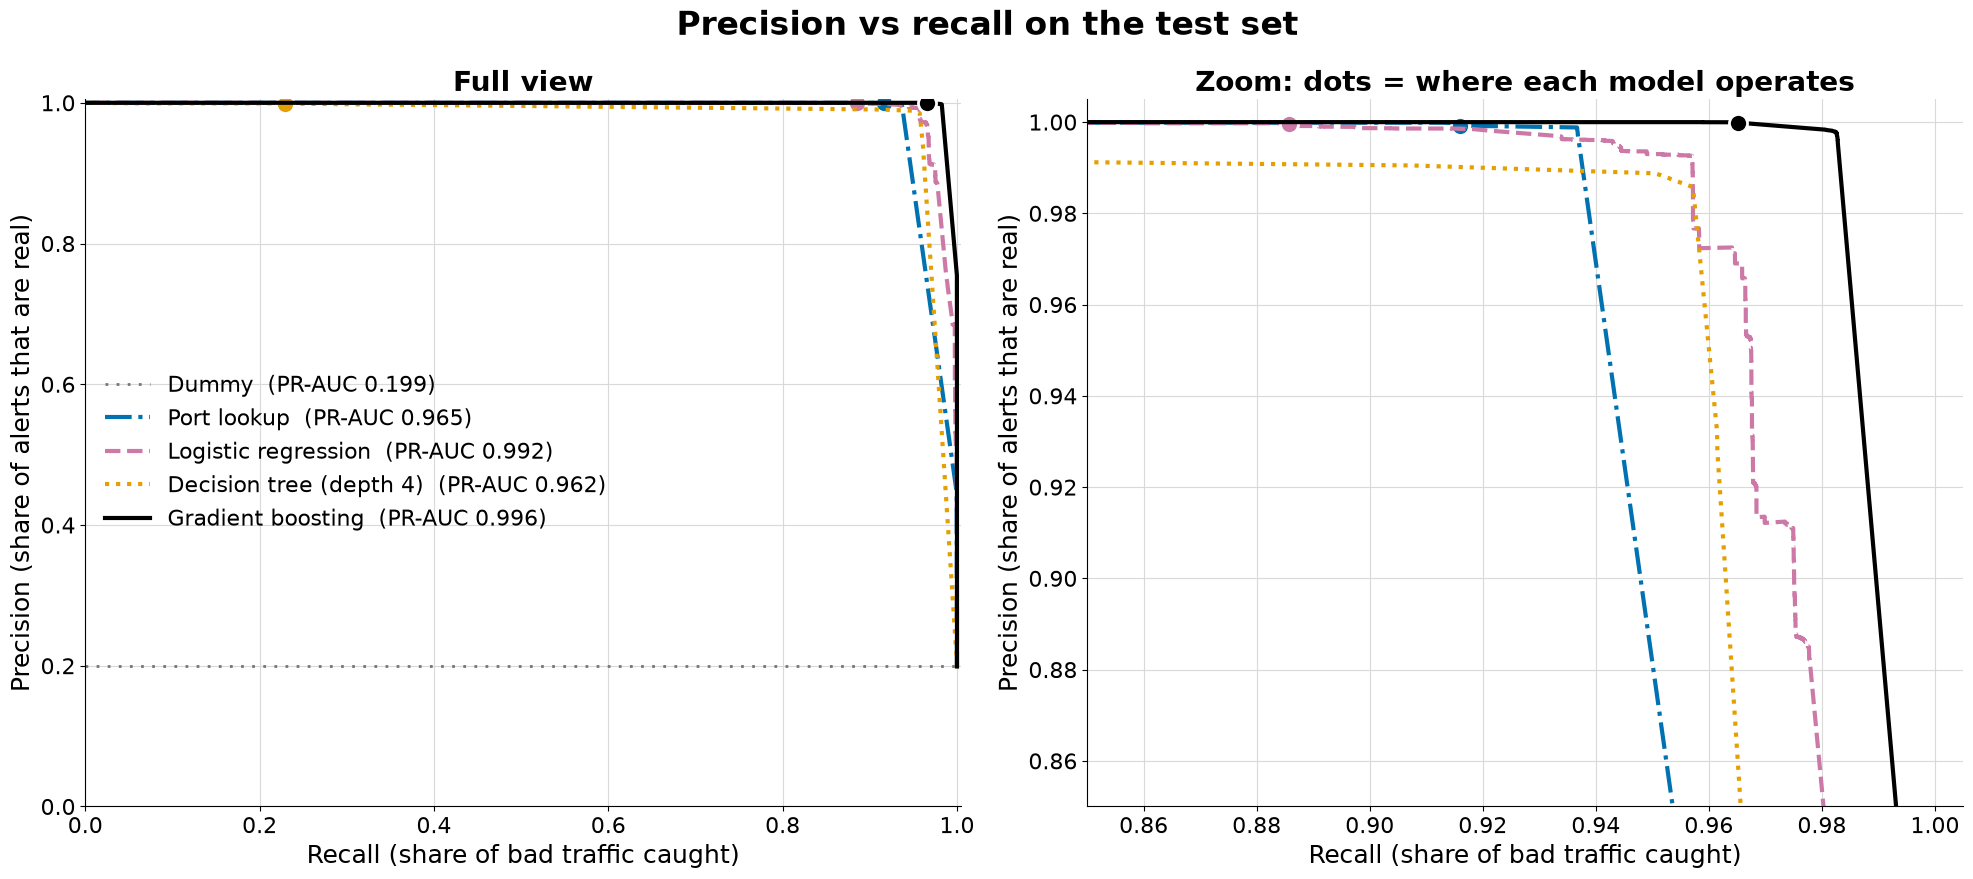

In [16]:
styles = {"port_lookup": ("#0072B2", "-."), "logistic_regression": ("#CC79A7", "--"),
          "decision_tree": ("#E69F00", ":"), "hist_gradient_boosting": ("#000000", "-")}
points = {}  # where each model operates: recall and precision at its own validation threshold
for name in styles:
    hits = models[name].predict_proba(test[FEATURES])[:, 1] >= on_validation.loc[name, "threshold"]
    points[name] = (hits[y_test == 1].mean(), y_test[hits].mean())
zoom_low = math.floor((min(r for r, _ in points.values() if r > 0.5) - 0.03) * 20) / 20

fig, axes = plt.subplots(1, 2, figsize=(20, 9))
for ax, low, title in [(axes[0], 0.0, "Full view"), (axes[1], zoom_low, "Zoom: dots = where each model operates")]:
    ax.axhline(y_test.mean(), color="#767676", linestyle=(0, (1, 3)), linewidth=2,
               label=f"Dummy  (PR-AUC {table.loc['dummy', 'test_pr_auc']:.3f})")
    for name, (color, linestyle) in styles.items():
        precision, recall, _ = precision_recall_curve(y_test, models[name].predict_proba(test[FEATURES])[:, 1])
        ax.plot(recall, precision, color=color, linestyle=linestyle,
                label=f"{NAMES[name]}  (PR-AUC {table.loc[name, 'test_pr_auc']:.3f})")
        ax.plot(*points[name], marker="o", markersize=13, color=color, markeredgecolor="white",
                markeredgewidth=2, linestyle="none")
    ax.set_xlim(low, 1.005)
    ax.set_ylim(low, 1.005)
    ax.set_xlabel("Recall (share of bad traffic caught)", fontsize=18)
    ax.set_ylabel("Precision (share of alerts that are real)", fontsize=18)
    ax.tick_params(labelsize=16)
    ax.set_title(title, fontsize=20)
axes[0].legend(loc="center left", frameon=False, fontsize=16)
fig.suptitle("Precision vs recall on the test set", fontsize=24, fontweight="bold")
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "05_pr_curves.png")
plt.show()

- **Boosting holds on test:** recall 96.5% (malicious 96.6%, outlier 96.3%), and 8 false alarms among 75,437
  alerts. That is about **40 false alarms a day, with a 95% range of 20 to 79**, well inside the ~157 budget.
- **Coarse models carry their thresholds less well.** The port lookup flags whole (protocol, port) groups. Every
  benign flow to a mostly-bad port becomes a false alarm (9 to HTTP/80, 7 to NetBIOS/137), and a rare port's score
  rests on a handful of training flows (13 benign flows to TCP/41980). On test it raises about 280 false alarms a
  day, 1.8x the budget. Logistic regression stays inside (about 120).
- Boosting's 8 false alarms are scattered (4 to TCP ephemeral ports, the rest one each): no sign of a single defect
  like the one in section 10.
- In figure 05 the learned models look close by area (PR-AUC 0.962 to 0.996). The dots show the real difference:
  boosting operates further right (more recall) and at the top (almost no false alarms).

**Decision:** report the test result with its 95% range. It confirms the choice, and nothing is re-tuned.

## 7. Is it memorizing? Repeated vs new flows

**Question:** only exact copies were dropped, so the same 10 inputs can appear in train and test (the same
behaviour from another IP or at another time). Is the test score mostly memory?

In [17]:
# A test flow "repeats" a training flow when all 10 model inputs are identical.
seen = train[FEATURES].drop_duplicates().assign(seen_in_train=True)
repeated = test[FEATURES].merge(seen, how="left", on=FEATURES)["seen_in_train"].fillna(False).astype(bool).to_numpy()
pd.DataFrame({
    "share of test": [f"{repeated.mean():.1%}", f"{(~repeated).mean():.1%}"],
    "recall": [f"{flagged[repeated & (y_test == 1)].mean():.1%}", f"{flagged[~repeated & (y_test == 1)].mean():.1%}"],
    "false-positive rate": [f"{flagged[repeated & (y_test == 0)].mean():.4%}",
                            f"{flagged[~repeated & (y_test == 0)].mean():.4%}"],
}, index=["repeated flows", "new flows"])

,share of test,recall,false-positive rate
repeated flows,26.4%,95.3%,0.0039%
new flows,73.6%,97.1%,0.0021%


26.4% of test flows repeat a training flow exactly. Recall is **95.3%** on those and **97.1%** on new ones: the
model does better on flows it has never seen, so the score is not mostly memory. False-positive rates are tiny in
both groups (0.0039% and 0.0021%).

**Decision:** keep the random split as the main test, with this check next to it. It does not test new
attackers: that needs an "unseen attacker" split (README, "With more time").

## 8. Does it hold later in the day? Time-based check

**Question:** production runs from past to future. Train the same model on the first 60% of flows in time order,
set its threshold on the next 20%, then test on the last 20% without touching the threshold.

In [18]:
# prepare_dataset sorted the flows by time. The cut is by number of flows, not by clock hours.
n = len(clean)
past, recent, future = clean.iloc[:int(n * 0.6)], clean.iloc[int(n * 0.6):int(n * 0.8)], clean.iloc[int(n * 0.8):]
time_model = clone(candidate_models()[chosen]).fit(past[FEATURES], past[TARGET])
recent_threshold = threshold_for_budget(recent[TARGET], time_model.predict_proba(recent[FEATURES])[:, 1])
future_scores = time_model.predict_proba(future[FEATURES])[:, 1]
later = at_threshold(future[TARGET], future_scores, recent_threshold)
retuned = at_threshold(future[TARGET], future_scores, threshold_for_budget(future[TARGET], future_scores))


def window(part: pd.DataFrame) -> str:
    return f"{part['event_time'].iloc[0]:%H:%M} to {part['event_time'].iloc[-1]:%H:%M}"


budget_per_day = config.MAX_FALSE_POSITIVE_RATE * PER_DAY
pd.Series({
    "train on (UTC)": window(past),
    "set the threshold on": window(recent),
    "test on": window(future),
    "threshold": f"{recent_threshold:.4f}",
    "recall": f"{later['recall']:.1%}",
    "false alarms a day": f"{later['false_alarms_per_day']:,.0f} ({later['false_alarms_per_day'] / budget_per_day:.0f}x the budget)",
    "recall if re-tuned on the test period": f"{retuned['recall']:.1%}",
}).to_frame("value")

,value
train on (UTC),23:59 to 17:12
set the threshold on,17:12 to 17:37
test on,17:37 to 23:59
threshold,0.1468
recall,99.1%
false alarms a day,"2,061 (13x the budget)"
recall if re-tuned on the test period,97.8%


In [19]:
later_flagged = future_scores >= recent_threshold
groups = false_alarm_groups(future[FEATURES], later_flagged & (future[TARGET] == 0).to_numpy())
print(f"Later traffic: {groups.sum()} false alarms. Biggest groups: {groups.head(4).to_dict()}")

Later traffic: 393 false alarms. Biggest groups: {'17/5353': 55, '6/ephemeral': 44, '6/1': 22, '6/39094': 16}


Recall holds (**99.1%**), but false alarms jump to about **2,060 a day, 13 times the budget**. Because of the
afternoon burst, the threshold window covers only 25 minutes (17:12 to 17:37) of mostly benign traffic, so the
threshold (0.147) is far too low for the evening. Re-tuned on the test period, recall would be 97.8% inside the
budget: the ranking still works, but the threshold drifted. The biggest groups of later false alarms are UDP/5353
(mDNS), TCP to ephemeral ports, and TCP/1.

**Decision:** in production, monitor daily false alarms against the budget, and re-tune the threshold on recent,
representative traffic (`docs/production.md`).

## 9. What does it rely on? Permutation importance (figure 06)

**Question:** which inputs does the model actually use? Shuffle one input at a time on a 20,000-flow test sample
and measure how much PR-AUC drops.

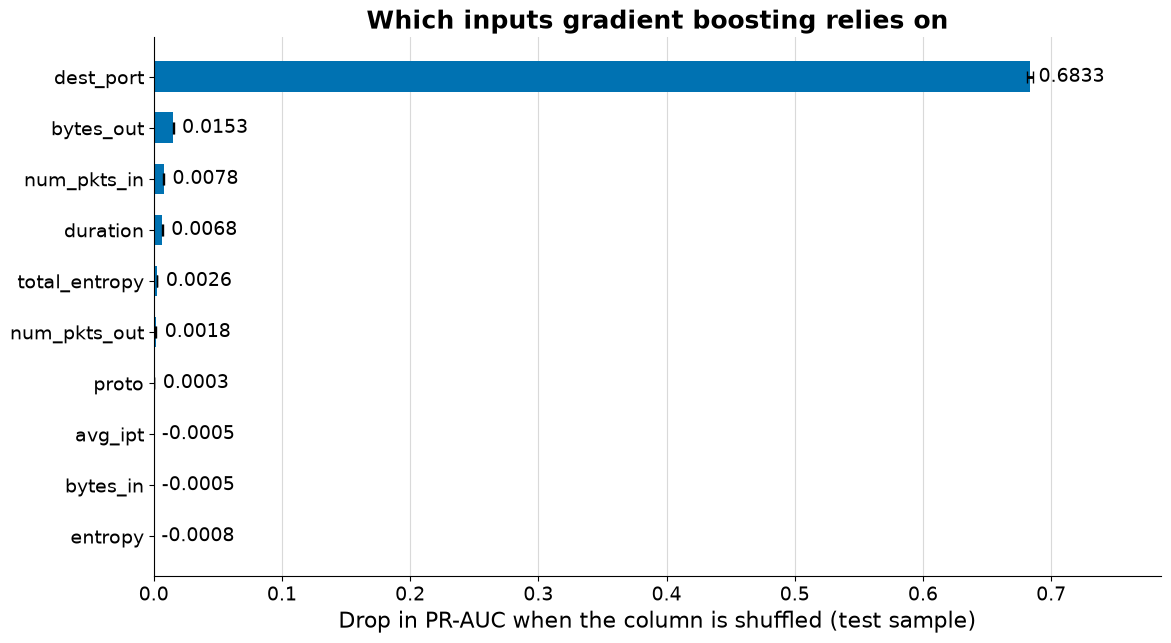

,mean,std
dest_port,0.6833,0.0022
bytes_out,0.0153,0.0006
num_pkts_in,0.0078,0.0003
duration,0.0068,0.0005
total_entropy,0.0026,0.0001
num_pkts_out,0.0018,0.0004
proto,0.0003,0.0001
avg_ipt,-0.0005,0.0002
bytes_in,-0.0005,0.0001
entropy,-0.0008,0.0001


In [20]:
sample = test.sample(20_000, random_state=config.RANDOM_STATE)
result = permutation_importance(model, sample[FEATURES], sample[TARGET], scoring="average_precision",
                                n_repeats=5, random_state=config.RANDOM_STATE)
importance = pd.DataFrame({"mean": result.importances_mean, "std": result.importances_std},
                          index=FEATURES).sort_values("mean", ascending=False)

ordered = importance.iloc[::-1]
fig, ax = plt.subplots(figsize=(13, 7))
ax.barh(ordered.index, ordered["mean"], xerr=ordered["std"], color="#0072B2", height=0.6,
        error_kw={"elinewidth": 2, "capsize": 4})
for i, value in enumerate(ordered["mean"]):
    ax.text(value + importance["mean"].max() * 0.01, i, f"{value:.4f}", va="center", fontsize=14)
ax.set_xlim(0, importance["mean"].max() * 1.15)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Drop in PR-AUC when the column is shuffled (test sample)")
ax.set_title(f"Which inputs {NAMES[chosen].lower()} relies on")
fig.savefig(config.FIGURES_DIR / "06_permutation_importance.png")
plt.show()
importance.round(4)

The destination port dominates (**0.683**). Next come bytes out (0.015), packets in (0.008) and duration (0.007).
Port 9200 (internal logging) is two thirds of benign traffic, so on this network the port partly means "internal".

**Decision:** say clearly that the model is specific to this network. The next version would add behaviour over
time per source, for example how many ports a source touched in the last minute.

## 10. Two mistakes found by review (in an earlier version)

After the first working version I ran two adversarial reviews with Claude Code agents: one agent looked for
problems, and a second agent tried to disprove each finding. Both mistakes were real. The numbers below were
**found in an earlier version** (80/20 split, threshold from cross-validation); the fixes are part of this one.

1. **De-duplication hid about 126,000 false alarms a day.** The first version removed every row that looked
   identical to the model. That changed how often patterns occur: an empty one-packet TCP flow to an ephemeral
   port is 95% benign in real traffic, but after de-duplication it looked 99% bad. The test set was de-duplicated
   the same way, so it reported about 92 false alarms a day, while scoring every raw flow of the day flagged
   126,136 benign flows. **Fix:** drop exact copies only, and evaluate on traffic as it arrives (`notebooks/01_eda.ipynb`).
2. **Runaway scores at the top.** Without regularization, gradient boosting gave 88 benign TCP/9200
   (Elasticsearch) flows a score of exactly 1.0, the highest possible. They were 88 of its 94 false alarms on the
   test set (about 470 a day, 3x the budget). It was found with the "false alarms by protocol/port" check in
   section 6. **Fix:** `l2_regularization=1.0` brought false alarms to 7 on the same test set (about 35 a day) at
   the same recall.

**Decision:** keep both checks in the process: score traffic as it arrives, and look at the biggest false-alarm
groups and the top of the score range before trusting a model.

## Summary: what model development decided

| Question | What I found | Decision |
|---|---|---|
| How do I keep the result honest? | 60/20/20 split; the same test set as before; 31 false alarms allowed on validation | Fit on train, choose on validation, test once |
| Where is each model's line? | Lowest score within 0.01% false positives; tied scores leave boosting at 15 a day | Compare models at the budget, not by PR-AUC |
| Are readable rules enough? | Depth-4 tree: 22.8% inside the budget; its leaves are too mixed | Not at this budget |
| Is a simple rule enough? | Port lookup: 91.8% on validation, but ~280 false alarms a day on test | No; it is the "why ML?" answer |
| Fast enough? | Every model is far above 4,500 flows/s in batches; one at a time, ~130/s | Score in small batches |
| Which model? | Boosting: 96.5% recall, 4.7 points above the next best | Serve gradient boosting |
| Does it hold on test? | 96.5% recall, ~40 false alarms a day (range 20 to 79) | Report the range |
| Is it memorizing? | 95.3% recall on repeated flows, 97.1% on new ones | Keep the random split; add an unseen-attacker split later |
| Does it hold later in the day? | 99.1% recall, but ~2,060 false alarms a day (13x) | Monitor alerts; re-tune the threshold on recent traffic |
| What drives it? | The destination port, by far | Results are specific to this network |